#Laguage Translation framework MVP

In [1]:
import pandas as pd
import os

#EDA

In [13]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from collections import Counter

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

In [14]:
vocab_df = pd.read_csv("toda_vocabulary.csv")
parallel_df = pd.read_csv("toda_parallel_sentences.csv")
grammar_df = pd.read_csv("toda_grammar_rules.csv")

In [15]:
def dataset_summary(df, name):
    print("=" * 60)
    print(name)
    print("=" * 60)

    print(f"Rows      : {df.shape[0]}")
    print(f"Columns   : {df.shape[1]}")
    print()

    print("Columns")
    print(df.columns.tolist())

    print("\nMissing Values")
    print(df.isnull().sum())

    print("\nDuplicate Rows")
    print(df.duplicated().sum())

    print("\nData Types")
    print(df.dtypes)

    print("\nSample")
    display(df.head())

In [16]:
dataset_summary(vocab_df,"Vocabulary")
dataset_summary(parallel_df,"Parallel Sentences")
dataset_summary(grammar_df,"Grammar Rules")

Vocabulary
Rows      : 89
Columns   : 5

Columns
['English', 'Toda', 'POS', 'Notes', 'Source']

Missing Values
English     0
Toda        0
POS         0
Notes      28
Source      0
dtype: int64

Duplicate Rows
0

Data Types
English    object
Toda       object
POS        object
Notes      object
Source     object
dtype: object

Sample


,English,Toda,POS,Notes,Source
0,water,nir,noun,monomorphemic noun,"Emeneau 1984, via Toda Language blog (Morphology page)"
1,salt,up,noun,monomorphemic noun,"Emeneau 1984, via Toda Language blog (Morphology page)"
2,man / Toda man,oɫ.,noun,monomorphemic noun,"Emeneau 1984, via Toda Language blog (Morphology page)"
3,moonlight,nes̠of,noun,monomorphemic noun,"Emeneau 1984, via Toda Language blog (Morphology page)"
4,butterfly,kopan.,noun,monomorphemic noun,"Emeneau 1984, via Toda Language blog (Morphology page)"


Parallel Sentences
Rows      : 12
Columns   : 4

Columns
['English', 'Toda', 'Type', 'Source']

Missing Values
English    0
Toda       0
Type       0
Source     0
dtype: int64

Duplicate Rows
0

Data Types
English    object
Toda       object
Type       object
Source     object
dtype: object

Sample


,English,Toda,Type,Source
0,You fried cakes.,"ni, pït. θut.s.pi.",statement,"Emeneau 1984, via Toda Language blog (Syntax page)"
1,That palace had seven stories.,"a kwat., öw midy oyčin.",statement,"Emeneau 1984, via Toda Language blog (Syntax page)"
2,The hand has become blistered.,"koy, ni pïkwïl.y xot.yfiči.",statement,"Emeneau 1984, via Toda Language blog (Syntax page)"
3,I will migrate with the buffaloes to the lower ti dairy.,"ki tik, ïr nar.kin.",statement,"Emeneau 1984, via Toda Language blog (Syntax page)"
4,They suffer pollution.,icïl fïd.θti.,statement,"Emeneau 1984, via Toda Language blog (Syntax page)"


Grammar Rules
Rows      : 16
Columns   : 4

Columns
['Rule ID', 'Description', 'Example', 'Source']

Missing Values
Rule ID        0
Description    0
Example        0
Source         0
dtype: int64

Duplicate Rows
0

Data Types
Rule ID        object
Description    object
Example        object
Source         object
dtype: object

Sample


,Rule ID,Description,Example,Source
0,G1,"Default sentence/constituent order is SOV (Subject-Object-Verb), as in other Dravidian languages, with some freedom in ordering S and O.",-,"Emeneau 1984:49, via Toda Language blog (Syntax page)"
1,G2,Plural nouns are commonly marked with the suffix -am.,-,"Emeneau 1984:69, via Toda Language blog (Morphology page)"
2,G3,Dative case is marked with suffix -k added to the oblique stem.,oɫ.k 'to the Toda'; ïrk 'to the buffalo'; kwïgk 'to the plains'; mor̠tk 'to the mund',"Emeneau 1984, via Toda Language blog (Morphology page)"
3,G4,"Locative case has 5 allomorphs of the suffix: -s, -š, -ž, -s., -z., added to the oblique stem.",kubs 'at the back'; poɫ.yš 'at the dairy'; muž 'in the vessel'; kwït.s. 'on the branch'; pos̠öz. 'at Nos. mund',"Emeneau 1984, via Toda Language blog (Morphology page)"
4,G5,Ablative case is marked with suffix -s̠n.,"kwïgs̠n, ker̠ïrk, tod. fodfïs.k ïd̠ti 'An army came from the plains to Ker̠ïr -- so they say.'","Emeneau 1984, via Toda Language blog (Morphology page)"


In [17]:
print("Unique English Words :", vocab_df["English"].nunique())

Unique English Words : 89


In [18]:
print("Unique Toda Words :", vocab_df["Toda"].nunique())

Unique Toda Words : 89


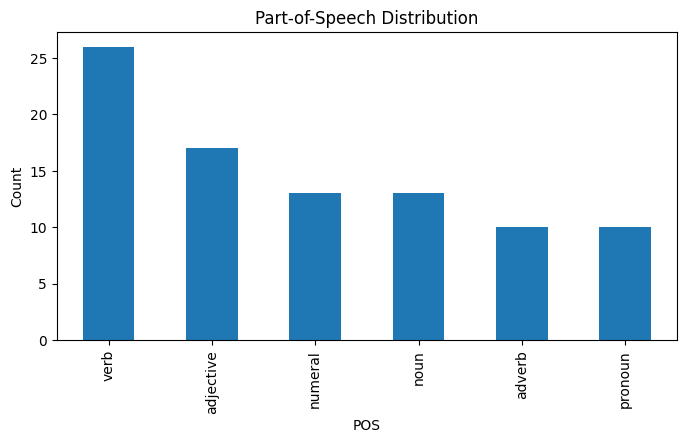

In [20]:
vocab_df["POS"].value_counts().plot.bar(figsize=(8,4))

plt.title("Part-of-Speech Distribution")

plt.ylabel("Count")

plt.show()

In [21]:
#Longest Toda word
vocab_df["Length"] = vocab_df["Toda"].str.len()

vocab_df.sort_values("Length",ascending=False).head()

,English,Toda,POS,Notes,Source,Length
39,small,kïr̠ or kin,adjective,precedes noun; no gender/number agreement,"Emeneau 1984, via Toda Language blog (Morphology page)",11
45,black,ka- or kax,adjective,NaN,"Emeneau 1984, via Toda Language blog (Morphology page)",10
38,big,per or ït,adjective,precedes noun; no gender/number agreement,"Emeneau 1984, via Toda Language blog (Morphology page)",9
84,hatch (S2),kwïl.d-,verb,S2 = S1 + -d-,"Emeneau 1984, via Toda Language blog (Morphology page)",7
56,first (in time) / before,maxar̠,adverb,NaN,"Emeneau 1984, via Toda Language blog (Morphology page)",6


In [24]:
#Vocabulary Coverage
Counter(vocab_df["POS"])

Counter({'noun': 13,
         'adverb': 10,
         'pronoun': 10,
         'numeral': 13,
         'adjective': 17,
         'verb': 26})

In [27]:
parallel_df["English Length"] = (
    parallel_df["English"]
    .str.split()
    .str.len()
)

In [28]:
parallel_df["Toda Length"] = (
    parallel_df["Toda"]
    .str.split()
    .str.len()
)

In [29]:
parallel_df[[
    "English Length",
    "Toda Length"
]].describe()

,English Length,Toda Length
count,12.000000,12.000000
mean,5.583333,4.250000
std,2.503028,2.378884
min,3.000000,2.000000
25%,3.750000,3.000000
50%,5.000000,4.000000
75%,7.250000,5.000000
max,11.000000,11.000000


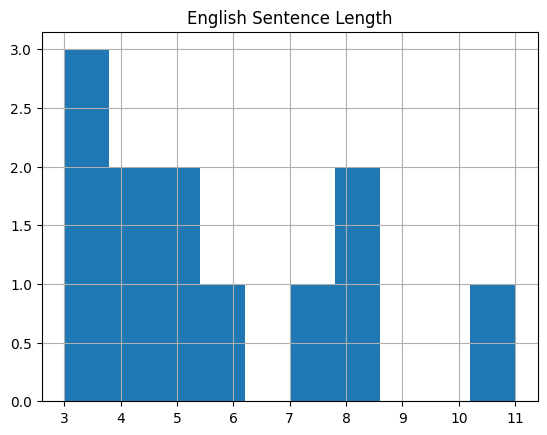

In [30]:
parallel_df["English Length"].hist()

plt.title("English Sentence Length")

plt.show()

In [31]:
len(grammar_df)

16

In [32]:
grammar_df[[
    "Rule ID",
    "Description"
]]

,Rule ID,Description
0,G1,"Default sentence/constituent order is SOV (Subject-Object-Verb), as in other Dravidian languages, with some freedom in ordering S and O."
1,G2,Plural nouns are commonly marked with the suffix -am.
2,G3,Dative case is marked with suffix -k added to the oblique stem.
3,G4,"Locative case has 5 allomorphs of the suffix: -s, -š, -ž, -s., -z., added to the oblique stem."
4,G5,Ablative case is marked with suffix -s̠n.
5,G6,"Instrumental case (means) is marked with suffix -ït̠, meaning 'by means of, with', added to noun stems."
6,G7,"Causative sense on nouns is marked with suffix -ïd, meaning 'because of', added to noun stems."
7,G8,"Sociative ('with, along with') is formed in two ways: (1) noun + -pod̠y 'following after'; (2) noun + suffix -wïr̠ 'with'."
8,G9,"Verbs have two stems, S1 and S2. S2 is derived from S1 by one of several class-specific suffixes: -y-, -θ-, -t-, or -d-."
9,G10,"Both past tense and present-future tense forms are built on the S2 stem, with person/number suffixes; there are also tenseless verb forms."


#KNOWLEDGE BASE

In [33]:
import pandas as pd
import json
from pathlib import Path

In [34]:
vocab_df = pd.read_csv("toda_vocabulary.csv")
grammar_df = pd.read_csv("toda_grammar_rules.csv")
parallel_df = pd.read_csv("toda_parallel_sentences.csv")

In [35]:
vocab_df["English"] = (
    vocab_df["English"]
    .str.lower()
    .str.strip()
)

vocab_df["Toda"] = (
    vocab_df["Toda"]
    .str.strip()
)

vocab_df["POS"] = (
    vocab_df["POS"]
    .str.lower()
)

In [36]:
lexicon = {}

for _, row in vocab_df.iterrows():

    lexicon[row["English"]] = {
        "toda": row["Toda"],
        "pos": row["POS"],
        "notes": row["Notes"],
        "source": row["Source"]
    }

In [37]:
lexicon["water"]

{'toda': 'nir',
 'pos': 'noun',
 'notes': 'monomorphemic noun',
 'source': 'Emeneau 1984, via Toda Language blog (Morphology page)'}

In [38]:
reverse_lexicon = {}

for _, row in vocab_df.iterrows():

    reverse_lexicon[row["Toda"]] = {
        "english": row["English"],
        "pos": row["POS"]
    }

In [39]:
grammar = {}

for _, row in grammar_df.iterrows():

    grammar[row["Rule ID"]] = {
        "description": row["Description"],
        "example": row["Example"],
        "source": row["Source"]
    }

In [40]:
grammar["G1"]

{'description': 'Default sentence/constituent order is SOV (Subject-Object-Verb), as in other Dravidian languages, with some freedom in ordering S and O.',
 'example': '-',
 'source': 'Emeneau 1984:49, via Toda Language blog (Syntax page)'}

In [41]:
parallel_corpus = []

for _, row in parallel_df.iterrows():

    parallel_corpus.append({

        "english": row["English"],

        "toda": row["Toda"],

        "type": row["Type"]
    })

In [42]:
def lookup_word(word):

    return lexicon.get(word.lower())

In [43]:
lookup_word("water")

{'toda': 'nir',
 'pos': 'noun',
 'notes': 'monomorphemic noun',
 'source': 'Emeneau 1984, via Toda Language blog (Morphology page)'}

In [44]:
def lookup_rule(rule_id):

    return grammar.get(rule_id)

In [45]:
def word_exists(word):

    return word.lower() in lexicon

In [46]:
Path("knowledge_base").mkdir(exist_ok=True)

In [47]:
with open("knowledge_base/lexicon.json","w") as f:

    json.dump(lexicon,f,indent=4)

In [48]:
with open("knowledge_base/grammar.json","w") as f:

    json.dump(grammar,f,indent=4)

#ENGLISH SEMANTIC PARSER

In [49]:
import spacy
import pandas as pd
import spacy

In [50]:
nlp = spacy.load("en_core_web_sm")

In [52]:
sentence = "The boy drinks water."

doc = nlp(sentence)

for token in doc:
    print(f"{token.text:{12}} {token.pos_:{10}} {token.tag_:{8}} {spacy.explain(token.tag_)}")

The          DET        DT       determiner
boy          NOUN       NN       noun, singular or mass
drinks       VERB       VBZ      verb, 3rd person singular present
water        NOUN       NN       noun, singular or mass
.            PUNCT      .        punctuation mark, sentence closer


In [53]:
def extract_subject(doc):

    for token in doc:

        if token.dep_ == "nsubj":

            return token.lemma_

    return None

In [54]:
def extract_verb(doc):

    for token in doc:

        if token.pos_ == "VERB":

            return token.lemma_

    return None

In [55]:
def extract_object(doc):

    for token in doc:

        if token.dep_ in ("dobj","obj"):

            return token.lemma_

    return None

In [56]:
def detect_tense(doc):
    has_future_modal = False
    first_verb_tense = None

    for token in doc:
        if token.tag_ == "MD" and token.lemma_.lower() == "will":
            has_future_modal = True
        elif token.pos_ == "VERB" and first_verb_tense is None:
            if token.tag_ == "VBD" or token.tag_ == "VBN":
                first_verb_tense = "past"
            elif token.tag_ in ["VB", "VBP", "VBZ", "VBG"]:
                first_verb_tense = "present"

    if has_future_modal:
        return "future"
    elif first_verb_tense:
        return first_verb_tense
    else:
        return "unknown"

In [57]:
def detect_negation(doc):
    for token in doc:
        if token.lemma_.lower() == "not":
            return True
    return False

In [58]:
def detect_question(doc):
    # Check if the last token is a question mark
    if doc and doc[-1].text == '?':
        return True
    return False

In [59]:
def semantic_parse(sentence):
    doc = nlp(sentence)

    return {
        "subject": extract_subject(doc),
        "verb": extract_verb(doc),
        "object": extract_object(doc),
        "tense": detect_tense(doc),
        "negation": detect_negation(doc),
        "question": detect_question(doc)
    }

In [60]:
# Example usage:
semantic_parse("The boy drinks water.")

{'subject': 'boy',
 'verb': 'drink',
 'object': 'water',
 'tense': 'present',
 'negation': False,
 'question': False}

In [61]:
for sentence in parallel_df["English"]:

    print(semantic_parse(sentence))

{'subject': 'you', 'verb': 'fry', 'object': 'cake', 'tense': 'past', 'negation': False, 'question': False}
{'subject': 'palace', 'verb': 'have', 'object': 'story', 'tense': 'past', 'negation': False, 'question': False}
{'subject': 'hand', 'verb': 'become', 'object': None, 'tense': 'past', 'negation': False, 'question': False}
{'subject': 'I', 'verb': 'migrate', 'object': None, 'tense': 'future', 'negation': False, 'question': False}
{'subject': 'they', 'verb': 'suffer', 'object': 'pollution', 'tense': 'present', 'negation': False, 'question': False}
{'subject': 'son', 'verb': None, 'object': None, 'tense': 'unknown', 'negation': False, 'question': False}
{'subject': 'buffalo', 'verb': None, 'object': None, 'tense': 'unknown', 'negation': False, 'question': False}
{'subject': 'cake', 'verb': 'fry', 'object': None, 'tense': 'present', 'negation': False, 'question': True}
{'subject': 'that', 'verb': None, 'object': None, 'tense': 'unknown', 'negation': False, 'question': True}
{'subject':

#TRANSLATION ENGINE

In [62]:
from typing import Dict, List
import json

In [63]:
with open("knowledge_base/lexicon.json") as f:
    LEXICON = json.load(f)

with open("knowledge_base/grammar.json") as f:
    GRAMMAR = json.load(f)

In [66]:
from dataclasses import dataclass
from typing import List


@dataclass
class TranslationResult:
    english_sentence: str
    semantic_representation: dict
    translated_tokens: List[str]
    unknown_words: List[str]
    toda_sentence: str

In [100]:
def lookup(word: str):

    word = word.lower()

    if word in LEXICON:
        return {"toda": LEXICON[word]["toda"], "pos": LEXICON[word]["pos"]}

    return None

In [67]:
lookup("water")

'nir'

In [68]:
def translate_word(word):

    toda = lookup(word)

    if toda is None:

        return f"<UNK:{word}>"

    return toda

In [69]:
translate_word("water")

'nir'

In [70]:
translate_word("computer")

'<UNK:computer>'

In [101]:
def translate_semantics(semantic):

    translated = {}

    unknown = []

    for field in ["subject","verb","object"]:

        value = semantic.get(field)

        if value is None:
            continue

        toda_word = None
        pos = None
        is_pronoun = False

        # G13: Pronoun normalization
        if value.lower() in PRONOUNS:
            is_pronoun = True
            if field == "subject":
                toda_word = PRONOUNS[value.lower()]["subject"]
            else: # For object, assume oblique form
                toda_word = PRONOUNS[value.lower()]["oblique"]
            pos = "pronoun"

        if toda_word is None: # If not a pronoun, or pronoun form not found, or not a pronoun
            lookup_result = lookup(value)
            if lookup_result:
                toda_word = lookup_result["toda"]
                pos = lookup_result["pos"]

        if toda_word is None:

            translated[field] = {"toda": f"<UNK:{value}>", "pos": None}

            unknown.append(value)

        else:

            translated[field] = {"toda": toda_word, "pos": pos, "is_pronoun": is_pronoun}

    return translated, unknown

In [102]:
def apply_word_order(tokens_with_morph_info):

    subject_info = tokens_with_morph_info.get("subject", {})
    obj_info = tokens_with_morph_info.get("object", {})
    verb_info = tokens_with_morph_info.get("verb", {})

    subject = subject_info.get("toda", "")
    obj = obj_info.get("toda", "")
    verb = verb_info.get("toda", "")

    ordered = [

        subject,

        obj,

        verb

    ]

    ordered = [w for w in ordered if w]

    return ordered

In [73]:
def build_sentence(tokens):

    return " ".join(tokens)

In [74]:
def translate(english_sentence, semantic):

    translated, unknown = translate_semantics(semantic)

    ordered = apply_word_order(translated)

    sentence = build_sentence(ordered)

    return TranslationResult(

        english_sentence=english_sentence,

        semantic_representation=semantic,

        translated_tokens=ordered,

        unknown_words=unknown,

        toda_sentence=sentence

    )

In [ ]:
# Modified translate function to incorporate morphology
def translate(english_sentence, semantic):

    translated, unknown = translate_semantics(semantic)

    morphed = morph_sentence(translated, semantic)

    ordered = apply_word_order(morphed)

    sentence = build_sentence(ordered)

    return TranslationResult(

        english_sentence=english_sentence,

        semantic_representation=semantic,

        translated_tokens=ordered,

        unknown_words=unknown,

        toda_sentence=sentence

    )

In [79]:
semantic = {
    "subject":"boy",
    "verb":"drink",
    "object":"water"
}

result = translate(
    "The boy drinks water.",
    semantic
)

print("English")
print(result.english_sentence)
print()
print("Semantic")
print(result.semantic_representation)
print()
print("Toda")
print(result.toda_sentence)
print()
print("Unknown Words")
print(result.unknown_words)

English
The boy drinks water.

Semantic
{'subject': 'boy', 'verb': 'drink', 'object': 'water'}

Toda
<UNK:boy> nir <UNK:drink>

Unknown Words
['boy', 'drink']


In [81]:
results = []

for sentence in parallel_df["English"]:
    semantic = semantic_parse(sentence)
    result = translate(
        sentence,
        semantic
    )
    results.append(result)

In [82]:
unknown = []

for r in results:
    unknown.extend(r.unknown_words)

sorted(set(unknown))

['I',
 'become',
 'buffalo',
 'cake',
 'fry',
 'hand',
 'have',
 'learn',
 'man',
 'migrate',
 'palace',
 'pollution',
 'son',
 'story',
 'suffer',
 'that',
 'they',
 'trick',
 'who',
 'whose',
 'you']

In [83]:
for i, row in parallel_df.iterrows():
    print("="*70)
    print("English")
    print(row["English"])
    print()
    print("Reference")
    print(row["Toda"])
    print()
    print("Generated")
    print(results[i].toda_sentence)

English
You fried cakes.

Reference
ni, pït. θut.s.pi.

Generated
<UNK:you> <UNK:cake> <UNK:fry>
English
That palace had seven stories.

Reference
a kwat., öw midy oyčin.

Generated
<UNK:palace> <UNK:story> <UNK:have>
English
The hand has become blistered.

Reference
koy, ni pïkwïl.y xot.yfiči.

Generated
<UNK:hand> <UNK:become>
English
I will migrate with the buffaloes to the lower ti dairy.

Reference
ki tik, ïr nar.kin.

Generated
<UNK:I> <UNK:migrate>
English
They suffer pollution.

Reference
icïl fïd.θti.

Generated
<UNK:they> <UNK:pollution> <UNK:suffer>
English
That man's son Makas̠, too, was a fool.

Reference
an mox makas̠m, pït.n. oyčïn.

Generated
<UNK:son>
English
The kog foɫ.y buffalo is the mother buffalo.

Reference
kog foɫ.y ïr, toy oθi ti ïr, kog foɫ.y ïr xor̠ïyi.

Generated
<UNK:buffalo>
English
How many cakes did I fry?

Reference
on, et fït. θut.s.n.

Generated
<UNK:cake> <UNK:fry>
English
What is that?

Reference
aθ inu.

Generated
<UNK:that>
English
Who is that ma

#MORPHOLOGY ENGINE

**Problem**

Unfortunately, we don't know Toda morphology yet.

We only know

- Sentence order = SOV

We don't know

- Present suffix
- Past suffix
- Future suffix
- Plural marker
- Negative marker
- Case markers

So we should not invent Toda grammar.

Instead we'll build a generic morphology engine that reads grammar rules.

In [94]:
MORPH_RULES = {
    "plural": {
        "suffix": "am"
    },
    "dative": {
        "suffix": "k"
    },
    "ablative": {
        "suffix": "s̠n"
    },
    "instrumental": {
        "suffix": "ït̠"
    },
    "causative": {
        "suffix": "ïd"
    },
    "sociative": {
        "suffix": "wïr̠"
    }
}

PRONOUNS = {
    "i":{
        "subject":"on",
        "oblique":"en"
    },

    "you":{
        "subject":"ni",
        "oblique":"nïn"
    }
}

In [96]:
class MorphologyEngine:
    def __init__(self, rules):
        self.rules = rules

    def _apply_rule(self, word, rule_type):
        if word is None or word.startswith("<UNK:"):
            return word
        if rule_type not in self.rules:
            return word # No rule defined

        suffix = self.rules[rule_type].get("suffix", "")
        prefix = self.rules[rule_type].get("prefix", "")

        if suffix or prefix:
            return prefix + word + suffix
        return word # If suffix and prefix are empty, return word unchanged

    def apply_plural(self, word):
        return self._apply_rule(word, "plural")

    def apply_dative(self, word):
        return self._apply_rule(word, "dative")

    def apply_ablative(self, word):
        return self._apply_rule(word, "ablative")

    def apply_instrumental(self, word):
        return self._apply_rule(word, "instrumental")

    def apply_causative(self, word):
        return self._apply_rule(word, "causative")

    def apply_sociative(self, word):
        return self._apply_rule(word, "sociative")

    def apply_tense(self, verb, tense):
        if verb is None or verb.startswith("<UNK:"):
            return verb
        # Since specific tense suffixes are not in MORPH_RULES, indicate it
        if tense == "past":
            return f"{verb}+past"
        elif tense == "future":
            return f"{verb}+future"
        elif tense == "present": # For present, only indicate if it's explicitly 'present'
            return f"{verb}+present"
        return verb

    def apply_negation(self, verb, is_negated):
        if verb is None or verb.startswith("<UNK:"):
            return verb
        if is_negated:
            # Since specific negation rules are not in MORPH_RULES, indicate it
            return f"{verb}+neg"
        return verb

In [111]:
def get_pronoun(word, role='subject'):
    """G13: Handle pronoun normalization."""
    word_lower = word.lower()
    if word_lower in PRONOUNS:
        return PRONOUNS[word_lower].get(role, PRONOUNS[word_lower].get('subject'))
    return None

def translate_word(word, role='subject', is_plural=False, case=None):
    """Refactored Morphology Pipeline for a single word."""
    # 1. Pronoun Normalization (G13)
    toda_word = get_pronoun(word, 'oblique' if role == 'object' else 'subject')

    # 2. Dictionary Lookup if not a pronoun
    if not toda_word:
        lookup_res = lookup(word)
        if lookup_res:
            toda_word = lookup_res['toda']
        else:
            return f'<UNK:{word}>'

    # 3. Morphological Rule Application
    if is_plural:
        toda_word = morphology_engine.apply_plural(toda_word)

    if case == 'dative':
        toda_word = morphology_engine.apply_dative(toda_word)
    elif case == 'ablative':
        toda_word = morphology_engine.apply_ablative(toda_word)
    elif case == 'instrumental':
        toda_word = morphology_engine.apply_instrumental(toda_word)
    elif case == 'causative':
        toda_word = morphology_engine.apply_causative(toda_word)
    elif case == 'sociative':
        toda_word = morphology_engine.apply_sociative(toda_word)

    return toda_word

def generate_morphed_tokens(semantic):
    """Orchestrates morphology for the entire sentence."""
    morphed = {}

    if semantic.get('subject'):
        morphed['subject'] = {'toda': translate_word(semantic['subject'], role='subject')}

    if semantic.get('object'):
        morphed['object'] = {'toda': translate_word(semantic['object'], role='object')}

    if semantic.get('verb'):
        verb_root = translate_word(semantic['verb'], role='verb')
        if not verb_root.startswith('<UNK:'):
            if semantic.get('negation'):
                verb_root += '+neg'

            tense = semantic.get('tense')
            if tense == 'past':
                verb_root += '+past'
            elif tense == 'future':
                verb_root += '+future'
            elif tense == 'present':
                verb_root += '+present'
        morphed['verb'] = {'toda': verb_root}

    return morphed

In [112]:
def translate(english_sentence, semantic):
    """Final integration of the refactored pipeline."""
    # Use the new Morphological Rule Engine pipeline
    morphed_tokens = generate_morphed_tokens(semantic)

    # Apply SOV word order
    ordered_tokens = apply_word_order(morphed_tokens)

    # Build final string
    toda_sentence = build_sentence(ordered_tokens)

    # Collect unknown words
    unknown = [v['toda'].split(':')[1].replace('>', '')
               for k, v in morphed_tokens.items()
               if v['toda'].startswith('<UNK:')]

    return TranslationResult(
        english_sentence=english_sentence,
        semantic_representation=semantic,
        translated_tokens=ordered_tokens,
        unknown_words=unknown,
        toda_sentence=toda_sentence
    )

In [109]:
def get_pronoun(word, role='subject'):
    """G13: Handle personal pronoun normalization (Subject vs Oblique)."""
    word_lower = word.lower()
    if word_lower in PRONOUNS:
        return PRONOUNS[word_lower].get(role, PRONOUNS[word_lower].get('subject'))
    return None

def translate_word(word, role='subject', is_plural=False, case=None):
    """The Morphological Pipeline for a single word."""
    # 1. Pronoun Normalization (G13)
    toda_word = get_pronoun(word, 'oblique' if role == 'object' else 'subject')

    # 2. Dictionary Lookup if not a normalized pronoun
    if not toda_word:
        lookup_res = lookup(word)
        if lookup_res:
            toda_word = lookup_res['toda']
        else:
            return f'<UNK:{word}>'

    # 3. Morphological Rule Application (Dictionary -> Rules)
    if is_plural:
        toda_word = morphology_engine.apply_plural(toda_word)

    if case == 'dative':
        toda_word = morphology_engine.apply_dative(toda_word)
    elif case == 'ablative':
        toda_word = morphology_engine.apply_ablative(toda_word)
    elif case == 'instrumental':
        toda_word = morphology_engine.apply_instrumental(toda_word)
    elif case == 'causative':
        toda_word = morphology_engine.apply_causative(toda_word)
    elif case == 'sociative':
        toda_word = morphology_engine.apply_sociative(toda_word)

    return toda_word

def generate_morphed_tokens(semantic):
    """Orchestrates morphology for sentence components."""
    morphed = {}

    # Handle Subject
    if semantic.get('subject'):
        morphed['subject'] = {'toda': translate_word(semantic['subject'], role='subject')}

    # Handle Object
    if semantic.get('object'):
        # Dynamically detecting plural/case from semantic parser output in future steps
        morphed['object'] = {'toda': translate_word(semantic['object'], role='object')}

    # Handle Verb with Tense/Negation tagging
    if semantic.get('verb'):
        verb_root = translate_word(semantic['verb'], role='verb')
        if not verb_root.startswith('<UNK:'):
            if semantic.get('negation'):
                verb_root += '+neg'

            tense = semantic.get('tense')
            if tense == 'past':
                verb_root += '+past'
            elif tense == 'future':
                verb_root += '+future'
            elif tense == 'present':
                verb_root += '+present'
        morphed['verb'] = {'toda': verb_root}

    return morphed

In [110]:
def translate(english_sentence, semantic):
    """Integrates parsing, morphology, and word ordering."""
    # 1. Morphology Engine Pipeline
    morphed_tokens = generate_morphed_tokens(semantic)

    # 2. Apply Word Order (SOV)
    ordered_tokens = apply_word_order(morphed_tokens)

    # 3. Sentence Construction
    toda_sentence = build_sentence(ordered_tokens)

    # Extract unknown words for tracking
    unknown = [v['toda'].split(':')[1].replace('>', '')
               for k, v in morphed_tokens.items()
               if v['toda'].startswith('<UNK:')]

    return TranslationResult(
        english_sentence=english_sentence,
        semantic_representation=semantic,
        translated_tokens=ordered_tokens,
        unknown_words=unknown,
        toda_sentence=toda_sentence
    )

In [107]:
def get_pronoun(word, role='subject'):
    """G13: Handle pronoun normalization."""
    word_lower = word.lower()
    if word_lower in PRONOUNS:
        return PRONOUNS[word_lower].get(role, PRONOUNS[word_lower].get('subject'))
    return None

def translate_word(word, role='subject', is_plural=False, case=None):
    """Refactored Morphology Pipeline for a single word."""
    # 1. Pronoun Normalization (G13)
    toda_word = get_pronoun(word, 'oblique' if role == 'object' else 'subject')

    # 2. Dictionary Lookup if not a pronoun
    if not toda_word:
        lookup_res = lookup(word)
        if lookup_res:
            toda_word = lookup_res['toda']
        else:
            return f'<UNK:{word}>'

    # 3. Morphological Rule Application (Dictionary Lookup -> Rule Engine)
    if is_plural:
        toda_word = morphology_engine.apply_plural(toda_word)

    if case == 'dative':
        toda_word = morphology_engine.apply_dative(toda_word)
    elif case == 'ablative':
        toda_word = morphology_engine.apply_ablative(toda_word)
    elif case == 'instrumental':
        toda_word = morphology_engine.apply_instrumental(toda_word)
    elif case == 'causative':
        toda_word = morphology_engine.apply_causative(toda_word)
    elif case == 'sociative':
        toda_word = morphology_engine.apply_sociative(toda_word)

    return toda_word

def generate_morphed_tokens(semantic):
    """Orchestrates morphology for sentence components."""
    morphed = {}

    # Subject
    if semantic.get('subject'):
        morphed['subject'] = {'toda': translate_word(semantic['subject'], role='subject')}

    # Object
    if semantic.get('object'):
        # is_plural and case would be detected here in a complete semantic parse
        morphed['object'] = {'toda': translate_word(semantic['object'], role='object')}

    # Verb (Manual Tense/Negation tagging as requested)
    if semantic.get('verb'):
        verb_root = translate_word(semantic['verb'], role='verb')
        if not verb_root.startswith('<UNK:'):
            if semantic.get('negation'):
                verb_root += '+neg'
            if semantic.get('tense') == 'past':
                verb_root += '+past'
            elif semantic.get('tense') == 'future':
                verb_root += '+future'
            elif semantic.get('tense') == 'present':
                verb_root += '+present'
        morphed['verb'] = {'toda': verb_root}

    return morphed

In [108]:
def translate(english_sentence, semantic):
    """Final integration of the refactored pipeline."""
    # Morph tokens using the new engine
    morphed_tokens = generate_morphed_tokens(semantic)

    # Apply SOV word order
    ordered_tokens = apply_word_order(morphed_tokens)

    # Join sentence
    toda_sentence = build_sentence(ordered_tokens)

    # Track unknown words from morphed outputs
    unknown = [v['toda'].split(':')[1].replace('>', '') for k, v in morphed_tokens.items() if v['toda'].startswith('<UNK:')]

    return TranslationResult(
        english_sentence=english_sentence,
        semantic_representation=semantic,
        translated_tokens=ordered_tokens,
        unknown_words=unknown,
        toda_sentence=toda_sentence
    )

In [105]:
def get_pronoun(word, role="subject"):
    """G13: Handle pronoun normalization."""
    word_lower = word.lower()
    if word_lower in PRONOUNS:
        return PRONOUNS[word_lower].get(role, PRONOUNS[word_lower].get("subject"))
    return None

def translate_word(word, role="subject", is_plural=False, case=None):
    """Refactored Morphology Pipeline for a single word."""
    # 1. Pronoun Normalization (G13)
    toda_word = get_pronoun(word, "oblique" if role == "object" else "subject")

    # 2. Dictionary Lookup if not a pronoun
    if not toda_word:
        lookup_res = lookup(word)
        if lookup_res:
            toda_word = lookup_res["toda"]
        else:
            return f"<UNK:{word}>"

    # 3. Morphological Rule Application
    if is_plural:
        toda_word = morphology_engine.apply_plural(toda_word)

    if case == "dative":
        toda_word = morphology_engine.apply_dative(toda_word)
    elif case == "ablative":
        toda_word = morphology_engine.apply_ablative(toda_word)
    elif case == "instrumental":
        toda_word = morphology_engine.apply_instrumental(toda_word)
    elif case == "causative":
        toda_word = morphology_engine.apply_causative(toda_word)
    elif case == "sociative":
        toda_word = morphology_engine.apply_sociative(toda_word)

    return toda_word

def generate_morphed_tokens(semantic):
    """Orchestrates morphology for the entire sentence components."""
    morphed = {}

    # Subject
    if semantic.get("subject"):
        morphed["subject"] = {"toda": translate_word(semantic["subject"], role="subject")}

    # Object
    if semantic.get("object"):
        # Note: In a real scenario, case/plural would be detected by the parser
        morphed["object"] = {"toda": translate_word(semantic["object"], role="object")}

    # Verb (Applying placeholders for tense/negation as requested)
    if semantic.get("verb"):
        verb_root = translate_word(semantic["verb"], role="verb")
        if not verb_root.startswith("<UNK:"):
            if semantic.get("negation"):
                verb_root += "+neg"
            if semantic.get("tense") == "past":
                verb_root += "+past"
            elif semantic.get("tense") == "future":
                verb_root += "+future"
            elif semantic.get("tense") == "present":
                verb_root += "+present"
        morphed["verb"] = {"toda": verb_root}

    return morphed

In [106]:
def translate(english_sentence, semantic):
    """Final integration of the refactored pipeline."""
    # Morph tokens
    morphed_tokens = generate_morphed_tokens(semantic)

    # Apply SOV order
    ordered_tokens = apply_word_order(morphed_tokens)

    # Join sentence
    toda_sentence = build_sentence(ordered_tokens)

    # Track unknown words
    unknown = [v["toda"].split(":")[1].replace(">", "") for k, v in morphed_tokens.items() if v["toda"].startswith("<UNK:")]

    return TranslationResult(
        english_sentence=english_sentence,
        semantic_representation=semantic,
        translated_tokens=ordered_tokens,
        unknown_words=unknown,
        toda_sentence=toda_sentence
    )

In [97]:
morphology_engine = MorphologyEngine(MORPH_RULES)

def morph_sentence(translated_semantics, semantic_representation):
    morphed_tokens = {}

    if "verb" in translated_semantics and semantic_representation["tense"] != "unknown":
        original_verb = translated_semantics["verb"]
        morphed_verb = morphology_engine.apply_tense(original_verb, semantic_representation["tense"])
        morphed_tokens["verb"] = morphed_verb
    elif "verb" in translated_semantics:
        morphed_tokens["verb"] = translated_semantics["verb"]

    if "verb" in morphed_tokens and semantic_representation["negation"]:
        morphed_tokens["verb"] = morphology_engine.apply_negation(morphed_tokens["verb"], True)

    if "subject" in translated_semantics:
        morphed_tokens["subject"] = translated_semantics["subject"]

    if "object" in translated_semantics:
        morphed_tokens["object"] = translated_semantics["object"]

    return morphed_tokens

In [113]:
test_sentences = [
    "I drink water.", # Present
    "I drank water.",  # Past
    "I will drink water.", # Future
    "I do not drink water.", # Negative
    "You drank water." # Test pronoun
]

for i, sentence in enumerate(test_sentences):
    print(f"\n{'='*70}\nTest Case {i+1}: {sentence}\n{'='*70}")
    semantic_representation = semantic_parse(sentence)
    translation_result = translate(sentence, semantic_representation)

    print("English:", translation_result.english_sentence)
    print("Semantic Representation:", translation_result.semantic_representation)
    print("Translated Toda:", translation_result.toda_sentence)
    print("Unknown Words:", translation_result.unknown_words)


Test Case 1: I drink water.
English: I drink water.
Semantic Representation: {'subject': 'I', 'verb': 'drink', 'object': 'water', 'tense': 'present', 'negation': False, 'question': False}
Translated Toda: on nir <UNK:drink>
Unknown Words: ['drink']

Test Case 2: I drank water.
English: I drank water.
Semantic Representation: {'subject': 'I', 'verb': 'drink', 'object': 'water', 'tense': 'past', 'negation': False, 'question': False}
Translated Toda: on nir <UNK:drink>
Unknown Words: ['drink']

Test Case 3: I will drink water.
English: I will drink water.
Semantic Representation: {'subject': 'I', 'verb': 'drink', 'object': 'water', 'tense': 'future', 'negation': False, 'question': False}
Translated Toda: on nir <UNK:drink>
Unknown Words: ['drink']

Test Case 4: I do not drink water.
English: I do not drink water.
Semantic Representation: {'subject': 'I', 'verb': 'drink', 'object': 'water', 'tense': 'present', 'negation': True, 'question': False}
Translated Toda: on nir <UNK:drink>
Unknow

### Morphology Engine Demonstration
This section tests the specific morphological transformations for nouns: plurals and various cases.

In [114]:
morphology_demonstration = [
    {"word": "buffalo", "rule": "plural"},
    {"word": "house", "rule": "dative"},
    {"word": "knife", "rule": "instrumental"},
    {"word": "village", "rule": "ablative"},
    {"word": "friend", "rule": "sociative"}
]

print(f"{'Rule Type':<15} | {'Input Root':<15} | {'Morphed Result'}")
print("-" * 50)

for test in morphology_demonstration:
    root = test['word']
    rule = test['rule']

    if rule == 'plural':
        result = morphology_engine.apply_plural(root)
    elif rule == 'dative':
        result = morphology_engine.apply_dative(root)
    elif rule == 'instrumental':
        result = morphology_engine.apply_instrumental(root)
    elif rule == 'ablative':
        result = morphology_engine.apply_ablative(root)
    elif rule == 'sociative':
        result = morphology_engine.apply_sociative(root)

    print(f"{rule:<15} | {root:<15} | {result}")

Rule Type       | Input Root      | Morphed Result
--------------------------------------------------
plural          | buffalo         | buffaloam
dative          | house           | housek
instrumental    | knife           | knifeït̠
ablative        | village         | villages̠n
sociative       | friend          | friendwïr̠


#6

In [ ]:
import pandas as pd
df = pd.read_csv('./toda_grammar_rules.csv')
df.head(16)